# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import AerialCactusIdentificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/aerial_cactus_identification/train",
    "csv_file": "./data/aerial_cactus_identification/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = AerialCactusIdentificationDataset(dataset_config)

## Show images from the dataset

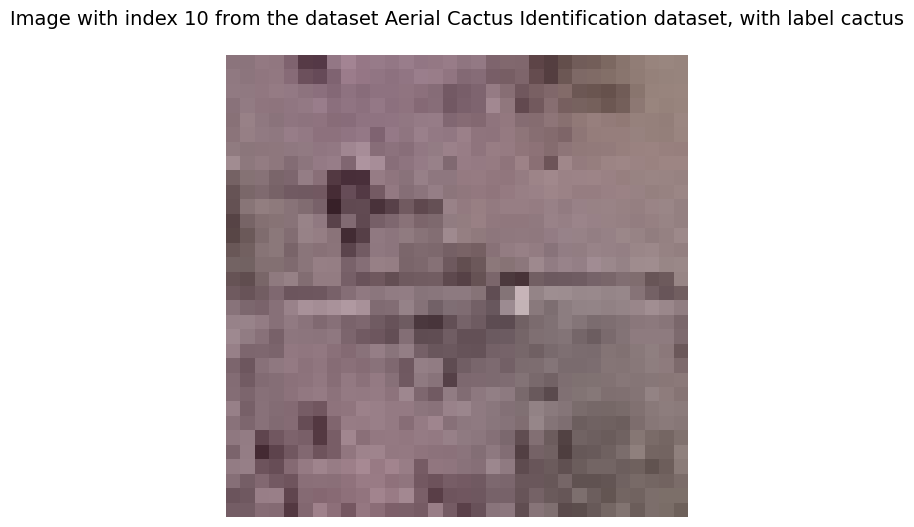

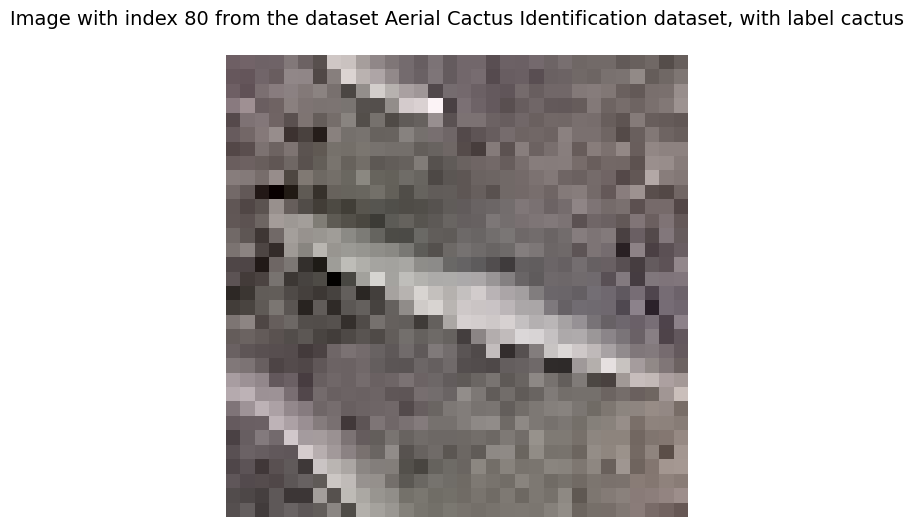

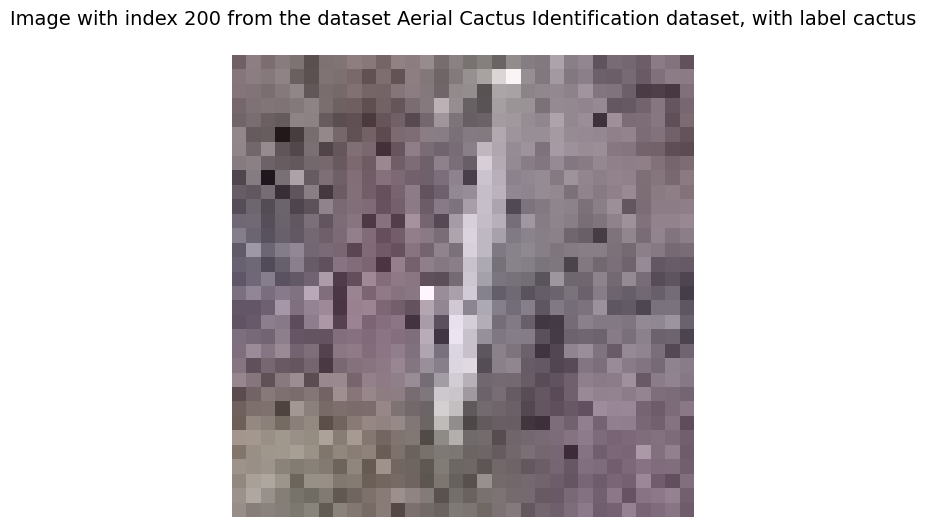

In [8]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

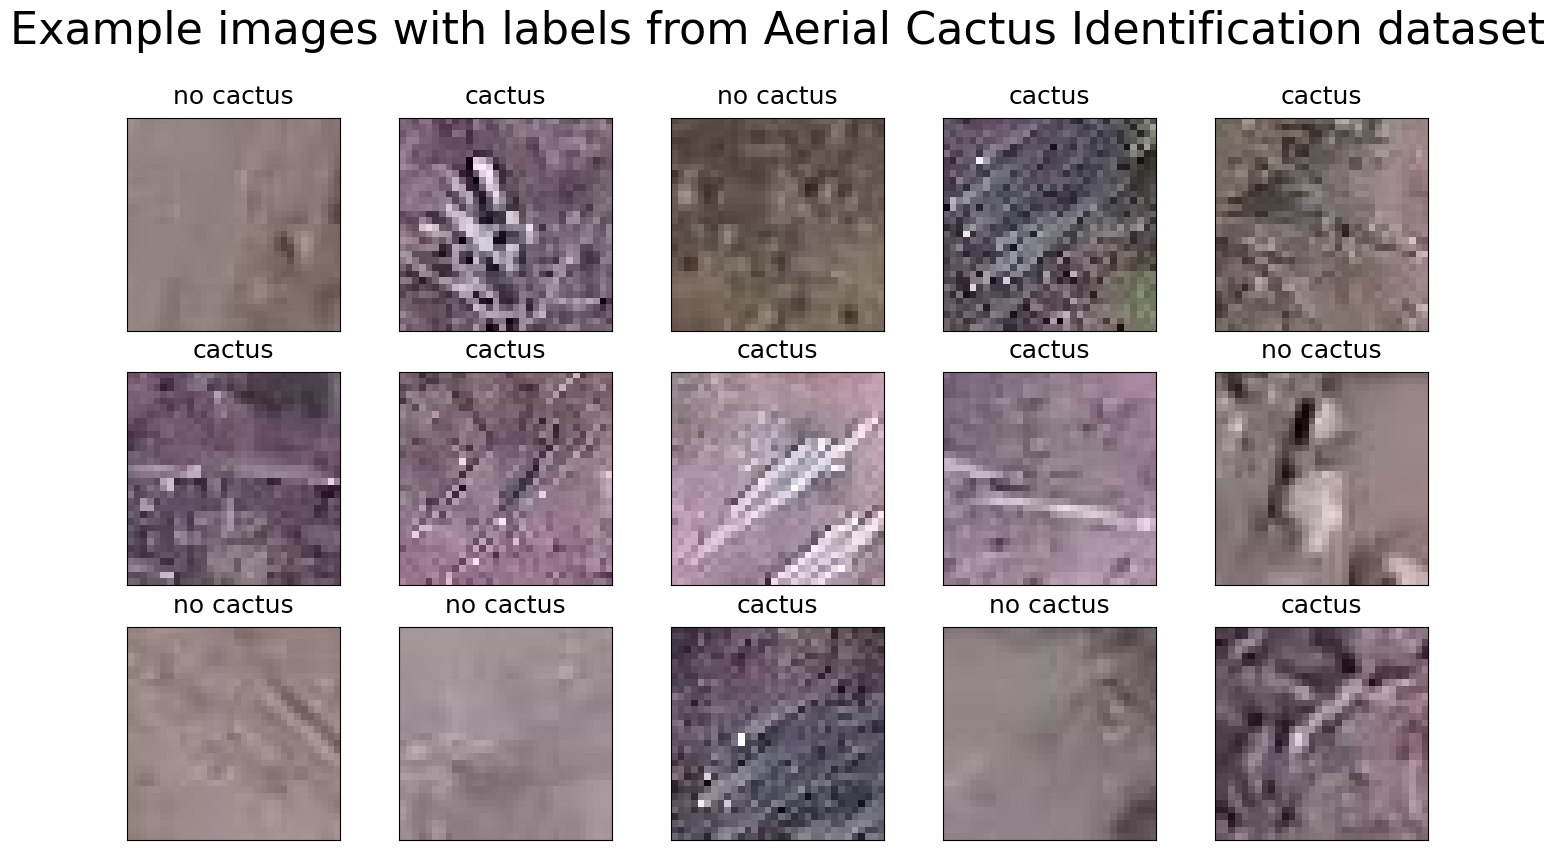

In [9]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [31]:
dataset.show_samples()

,File name,Label
1,0004be2cfeaba1c0361d39e2b000257b.jpg,cactus
2,000c8a36845c0208e833c79c1bffedd1.jpg,cactus
3,000d1e9a533f62e55c289303b072733d.jpg,cactus
4,0011485b40695e9138e92d0b3fb55128.jpg,cactus
5,0014d7a11e90b62848904c1418fc8cf2.jpg,cactus
6,0017c3c18ddd57a2ea6f9848c79d83d2.jpg,cactus
7,002134abf28af54575c18741b89dd2a4.jpg,no cactus
8,0024320f43bdd490562246435af4f90b.jpg,no cactus
9,002930423b9840e67e5a54afd4768a1e.jpg,cactus
10,00351838ebf6dff6e53056e00a1e307c.jpg,cactus


In [34]:
dataset.data_distribution_table()

,Label,Count
0,cactus,13136
1,no cactus,4364


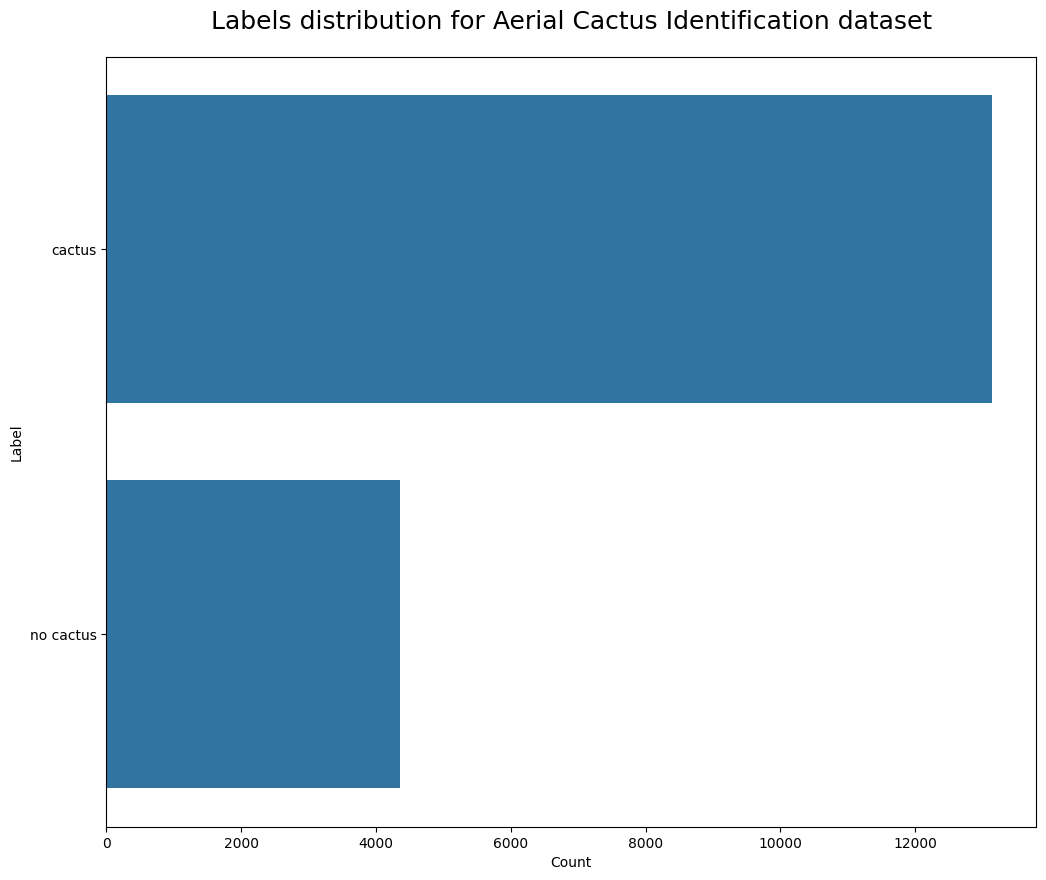

In [35]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/aerial_cactus_identification/train/",
    "csv_file": "./data/aerial_cactus_identification/train.csv",
}

train_dataset = AerialCactusIdentificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

len(train_dataset)

17500

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/aerial_cactus_identification/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-19 13:07:51,211 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-19 13:07:51,397 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [38]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

2025-05-19 13:07:53,384 INFO Starting training.
training: 100%|██████████| 547/547 [02:15<00:00,  4.04it/s]
2025-05-19 13:10:09,011 INFO epoch: 1, time: 136, loss:  0.04783
testing on train set: 100%|██████████| 547/547 [00:47<00:00, 11.55it/s]
2025-05-19 13:10:58,208 INFO Accuracy:0.9881714285714286, Precision Micro:0.9881714285714286, Precision Macro:0.9773572522423977, Precision Weighted:0.9887070912898084, Precision per Class:[0.9547145 1.       ], Recall Micro:0.9881714285714286, Recall Macro:0.9921208891595615, Recall Weighted:0.9881714285714286, Recall per Class:[1.         0.98424178], F1_score Micro:0.988171428571428, F1_score Macro:0.9844454981095747, F1_score Weighted:0.9882614773286498, F1_score per Class:[0.97683268 0.99205832]
training: 100%|██████████| 547/547 [02:16<00:00,  4.00it/s]
2025-05-19 13:13:15,051 INFO epoch: 2, time: 137, loss:  0.02767
testing on train set: 100%|██████████| 547/547 [00:47<00:00, 11.58it/s]
2025-05-19 13:14:02,315 INFO Accuracy:0.992285714285

0.015910338615574542

## Predictions

2025-05-19 13:42:43,755 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/aerial_cactus_identification/checkpoint.pth.tar
2025-05-19 13:42:44,071 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/aerial_cactus_identification/checkpoint.pth.tar at epoch 11


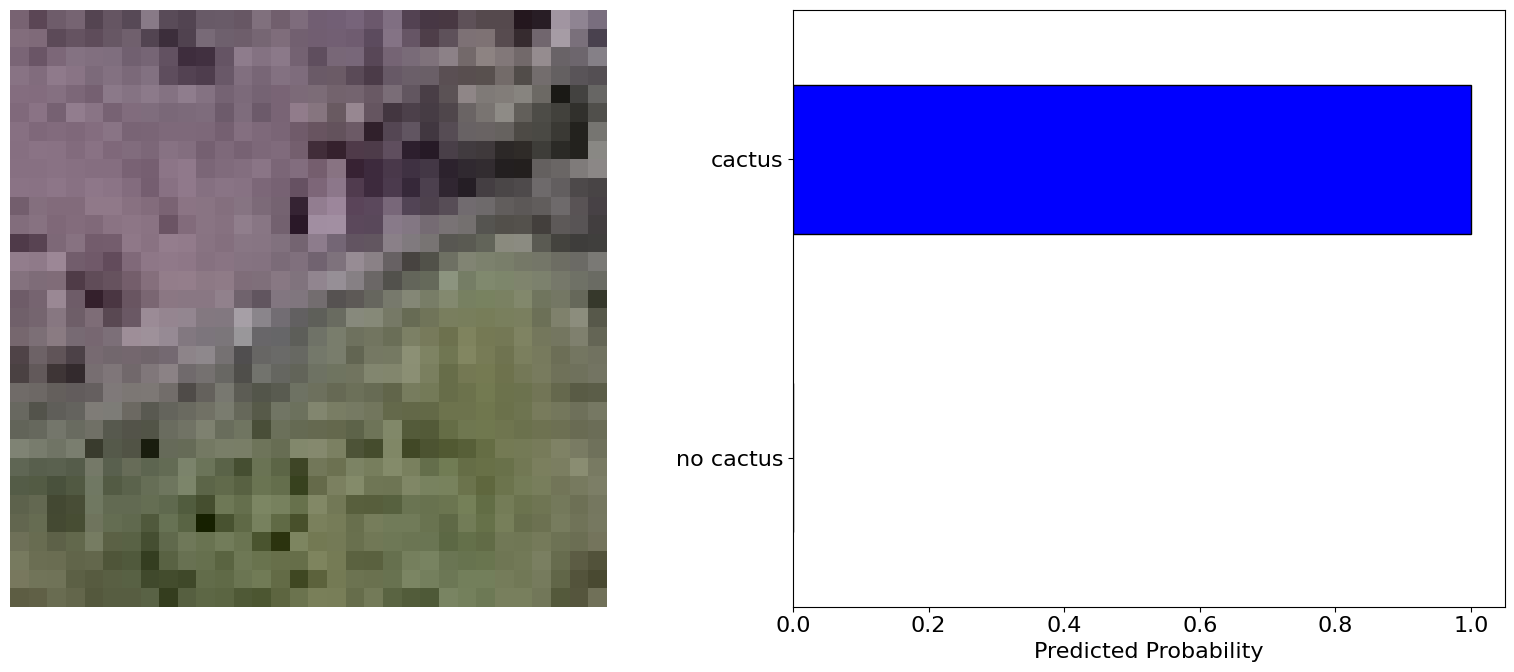

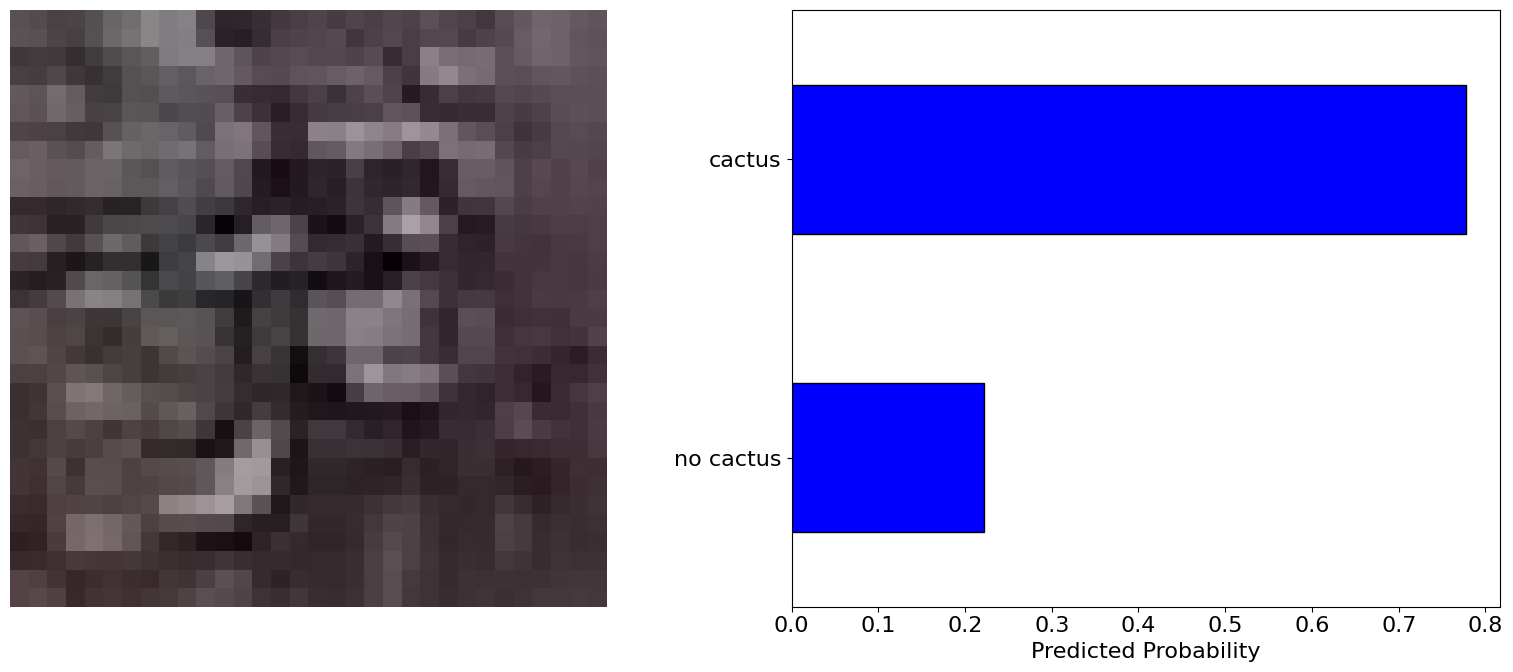

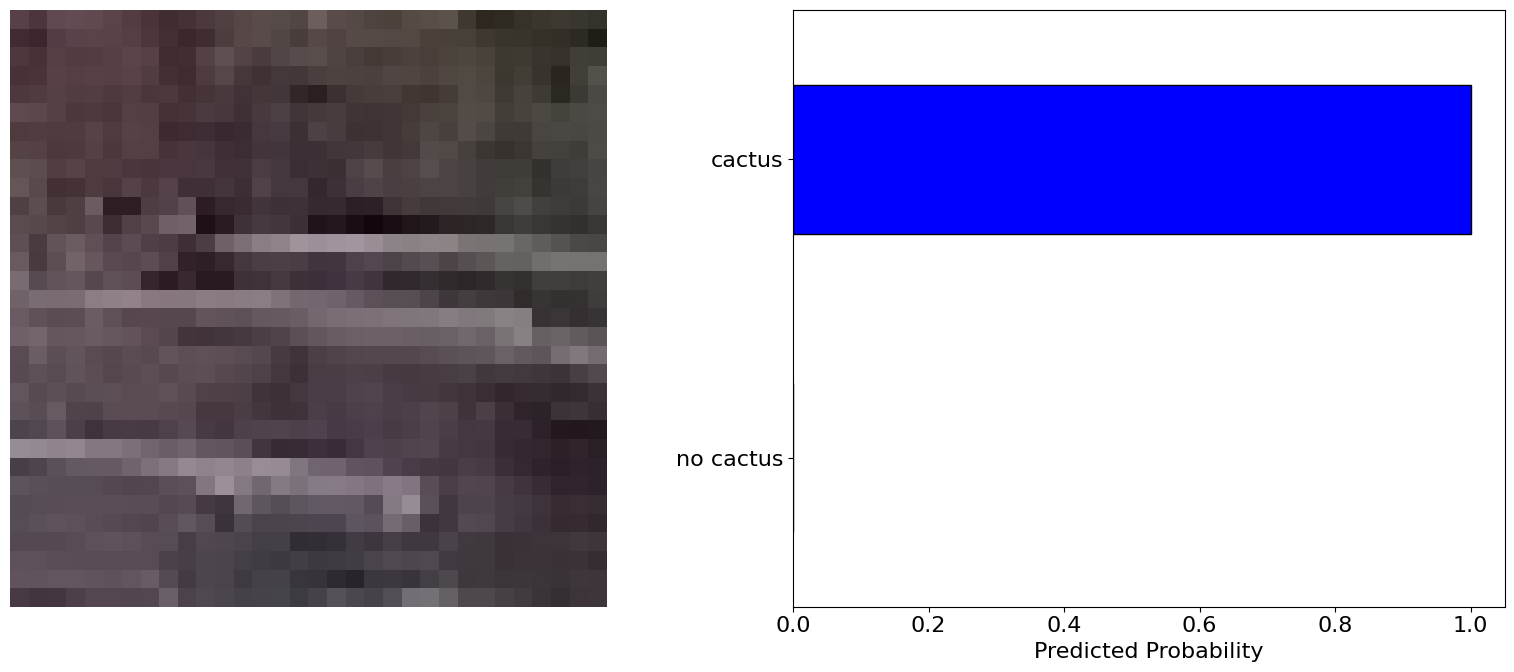

In [ ]:
labels = ["no cactus","cactus"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/aerial_cactus_identification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/aerial_cactus_identification/test/00e20b0e6d779e7c36cea29710eed88e.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/aerial_cactus_identification/test/0ade372540173b16dce90f598e869d82.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/aerial_cactus_identification/test/0cbbce0b5e86c310f8eb82ba4a17a000.jpg')
fig = model.predict_image(image, labels, transform)